## Lab 2

### Part 3. Poetry generation

Let's try to generate some poetry using RNNs. 

You have several choices here: 

* The Shakespeare sonnets, file `sonnets.txt` available in the notebook directory.

* Роман в стихах "Евгений Онегин" Александра Сергеевича Пушкина. В предобработанном виде доступен по [ссылке](https://github.com/attatrol/data_sources/blob/master/onegin.txt).

* Some other text source, if it will be approved by the course staff.

Text generation can be designed in several steps:
    
1. Data loading.
2. Dictionary generation.
3. Data preprocessing.
4. Model (neural network) training.
5. Text generation (model evaluation).


In [8]:
import string
import os
from time import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import copy

torch.manual_seed(0)
np.random.seed(0)

### Data loading: Shakespeare

Shakespeare sonnets are awailable at this [link](http://www.gutenberg.org/ebooks/1041?msg=welcome_stranger). In addition, they are stored in the same directory as this notebook (`sonnetes.txt`). Simple preprocessing is already done for you in the next cell: all technical info is dropped.

In [9]:
if not os.path.exists('sonnets.txt'):
    !wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_basic/homeworks_basic/lab02_deep_learning/sonnets.txt

with open('sonnets.txt', 'r') as iofile:
    text = iofile.readlines()
    
TEXT_START = 45
TEXT_END = -368
text = text[TEXT_START : TEXT_END]
assert len(text) == 2616

In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [10]:
text = ''.join(text).lower()

assert len(text) == 100225, 'Are you sure you have concatenated all the strings?'
assert not any([x in set(text) for x in string.ascii_uppercase]), 'Uppercase letters are present'
print('OK!')

OK!


Put all the characters, that you've seen in the text, into variable `tokens`.

In [11]:
tokens = sorted(set(text))
num_tokens = len(tokens)
print(num_tokens, repr(''.join(tokens)))

38 "\n !'(),-.:;?abcdefghijklmnopqrstuvwxyz"


Create dictionary `token_to_idx = {<char>: <index>}` and dictionary `idx_to_token = {<index>: <char>}`

In [12]:
idx_to_token = {idx: token for idx, token in enumerate(tokens)}

token_to_idx = {token: idx for idx, token in enumerate(tokens)}

encoded_text = torch.tensor([token_to_idx[token] for token in text], dtype=torch.long)
print(text[:60])
print(encoded_text[:60].tolist())

  from fairest creatures we desire increase,
  that thereby 
[1, 1, 17, 29, 26, 24, 1, 17, 12, 20, 29, 16, 30, 31, 1, 14, 29, 16, 12, 31, 32, 29, 16, 30, 1, 34, 16, 1, 15, 16, 30, 20, 29, 16, 1, 20, 25, 14, 29, 16, 12, 30, 16, 6, 0, 1, 1, 31, 19, 12, 31, 1, 31, 19, 16, 29, 16, 13, 36, 1]


*Comment: in this task we have only 38 different tokens, so let's use one-hot encoding.*

### Building the model

Now we want to build and train recurrent neural net which would be able to something similar to Shakespeare's poetry.

Let's use vanilla RNN, similar to the one created during the lesson.

In [13]:
SEQ_LENGTH = 100
BATCH_SIZE = 64
MAX_LENGTH = 500

split = int(0.9 * len(encoded_text))
train_data, val_data = encoded_text[:split], encoded_text[split:]
ITERATIONS_PER_EPOCH = len(train_data) // (BATCH_SIZE * SEQ_LENGTH)
print('train chars: %d, validation chars: %d, iterations per epoch: %d'
      % (len(train_data), len(val_data), ITERATIONS_PER_EPOCH))


def get_batch(data, batch_size=BATCH_SIZE, seq_length=SEQ_LENGTH):
    starts = torch.randint(0, len(data) - seq_length - 1, (batch_size,))
    x = torch.stack([data[s:s + seq_length] for s in starts])
    y = torch.stack([data[s + 1:s + seq_length + 1] for s in starts])
    return x, y


def evaluate(model, data, seq_length=SEQ_LENGTH):
    model.eval()
    n_chunks = (len(data) - 1) // seq_length
    x = data[:n_chunks * seq_length].view(n_chunks, seq_length)
    y = data[1:n_chunks * seq_length + 1].view(n_chunks, seq_length)
    with torch.no_grad():
        logits, _ = model(x, model.initial_state(n_chunks))
        loss = F.cross_entropy(logits.reshape(-1, num_tokens), y.reshape(-1))
    model.train()
    return loss.item()


def train(model, n_epochs, lr=2e-3, clip=5.0, verbose_every=10):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': []}
    best_state, best_val_loss = None, float('inf')
    model.train()
    start = time()
    for epoch in range(n_epochs):
        epoch_losses = []
        for _ in range(ITERATIONS_PER_EPOCH):
            x, y = get_batch(train_data)
            logits, _ = model(x, model.initial_state(BATCH_SIZE))
            loss = F.cross_entropy(logits.reshape(-1, num_tokens), y.reshape(-1))
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            epoch_losses.append(loss.item())
        history['train_loss'].append(np.mean(epoch_losses))
        history['val_loss'].append(evaluate(model, val_data))
        if history['val_loss'][-1] < best_val_loss:
            best_val_loss = history['val_loss'][-1]
            best_state = copy.deepcopy(model.state_dict())
        if (epoch + 1) % verbose_every == 0:
            print('epoch %3d | train loss %.3f | val loss %.3f | %.0f s'
                  % (epoch + 1, history['train_loss'][-1], history['val_loss'][-1], time() - start))
    model.load_state_dict(best_state)
    print('restored weights from epoch %d (validation loss %.3f)'
          % (int(np.argmin(history['val_loss'])) + 1, best_val_loss))
    return history

train chars: 90202, validation chars: 10023, iterations per epoch: 14


In [14]:
class CharRNN(nn.Module):
    def __init__(self, num_tokens, rnn_num_units=256):
        super().__init__()
        self.num_tokens = num_tokens
        self.rnn_num_units = rnn_num_units
        self.rnn_update = nn.Linear(num_tokens + rnn_num_units, rnn_num_units)
        self.rnn_to_logits = nn.Linear(rnn_num_units, num_tokens)

    def step(self, x, h_prev):
        x_onehot = F.one_hot(x, self.num_tokens).float()
        h_next = torch.tanh(self.rnn_update(torch.cat([x_onehot, h_prev], dim=1)))
        return self.rnn_to_logits(h_next), h_next

    def forward(self, x, h):
        logits = []
        for t in range(x.shape[1]):
            logits_t, h = self.step(x[:, t], h)
            logits.append(logits_t)
        return torch.stack(logits, dim=1), h

    def initial_state(self, batch_size):
        return torch.zeros(batch_size, self.rnn_num_units)


N_EPOCHS = 100

torch.manual_seed(0)
char_rnn = CharRNN(num_tokens)
print(char_rnn)
print('parameters:', sum(p.numel() for p in char_rnn.parameters()))
rnn_history = train(char_rnn, N_EPOCHS)

CharRNN(
  (rnn_update): Linear(in_features=294, out_features=256, bias=True)
  (rnn_to_logits): Linear(in_features=256, out_features=38, bias=True)
)
parameters: 85286
epoch  10 | train loss 2.117 | val loss 2.136 | 5 s
epoch  20 | train loss 1.953 | val loss 2.004 | 10 s
epoch  30 | train loss 1.815 | val loss 1.917 | 15 s
epoch  40 | train loss 1.702 | val loss 1.850 | 21 s
epoch  50 | train loss 1.611 | val loss 1.830 | 26 s
epoch  60 | train loss 1.518 | val loss 1.804 | 31 s
epoch  70 | train loss 1.445 | val loss 1.801 | 36 s
epoch  80 | train loss 1.377 | val loss 1.829 | 41 s
epoch  90 | train loss 1.304 | val loss 1.860 | 47 s
epoch 100 | train loss 1.249 | val loss 1.895 | 53 s
restored weights from epoch 68 (validation loss 1.788)


Plot the loss function (axis X: number of epochs, axis Y: loss function).

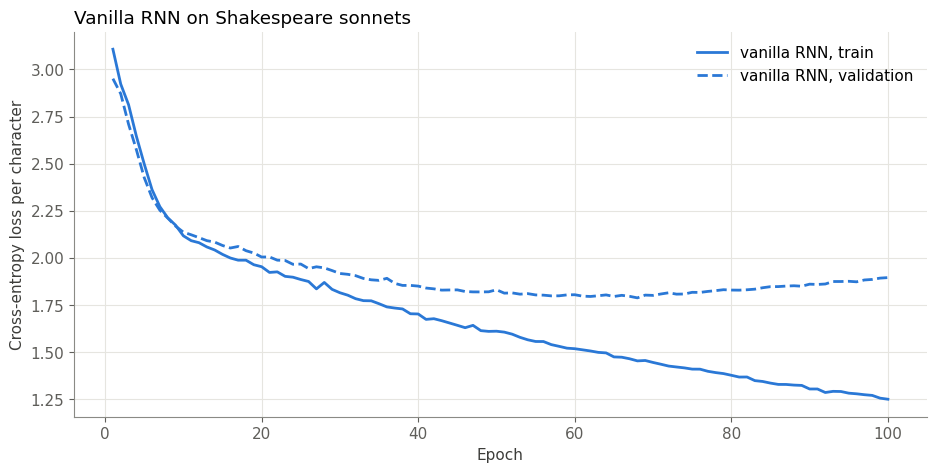

vanilla RNN: final train loss 1.249, final validation loss 1.895, best validation loss 1.788


In [15]:
SERIES_COLORS = ['#2a78d6', '#eb6834']
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#3d3d3a',
    'xtick.color': '#5f5e5a', 'ytick.color': '#5f5e5a',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 11,
})


def plot_losses(histories, title):
    fig, ax = plt.subplots(figsize=(11, 5))
    for color, (name, h) in zip(SERIES_COLORS, histories.items()):
        epochs = np.arange(1, len(h['train_loss']) + 1)
        ax.plot(epochs, h['train_loss'], '-', color=color, label=name + ', train')
        ax.plot(epochs, h['val_loss'], '--', color=color, label=name + ', validation')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Cross-entropy loss per character')
    ax.set_title(title, loc='left')
    ax.legend()
    plt.show()


plot_losses({'vanilla RNN': rnn_history}, 'Vanilla RNN on Shakespeare sonnets')
print('vanilla RNN: final train loss %.3f, final validation loss %.3f, best validation loss %.3f'
      % (rnn_history['train_loss'][-1], rnn_history['val_loss'][-1], min(rnn_history['val_loss'])))

In [16]:
def generate_sample(char_rnn, seed_phrase=' hello', max_length=MAX_LENGTH, temperature=1.0):
    char_rnn.eval()
    x_sequence = [token_to_idx[token] for token in seed_phrase.lower()]
    with torch.no_grad():
        logits, hid_state = char_rnn(torch.tensor([x_sequence]), char_rnn.initial_state(1))
        for _ in range(max_length - len(seed_phrase)):
            p_next = F.softmax(logits[0, -1] / temperature, dim=-1).numpy().astype(np.float64)
            next_ix = np.random.choice(num_tokens, p=p_next / p_next.sum())
            x_sequence.append(next_ix)
            logits, hid_state = char_rnn(torch.tensor([[next_ix]]), hid_state)
    char_rnn.train()
    return ''.join(idx_to_token[ix] for ix in x_sequence)

In [17]:
np.random.seed(0)
print(generate_sample(char_rnn, seed_phrase='shall i compare thee', temperature=0.5))

shall i compare thee thing thee my bedout in thine own me to grace and my heart has beart thou art and thee my self i san the sters the tinger me.

  xxvii

  the stoll's self i have to be all and that i to thee in thee sime
  thou art love's should have hape should fairer was when thou art burthing that which thou surte be resean appeared and thee though thee arate,
  then i thou thought still still thy ponterest and love's beak,
  and wheret on the liseliss and worth thee thee.

  xxxxii

  wh


**Vanilla RNN** 
Модель небольшая: 85тыс параметров. Train loss падает все 100 эпох, до 1.25. Validation loss минимален на 68й эпохе (1.79), после чего начинает расти, то есть начинается переобучение. Поэтому в `train` используется early stopping: в конце обучения восстанавливаются веса эпохи с лучшим validation loss, и текст выше сгенерирован именно этой моделью.

По тексту видно, что RNN выучила структуру сонетов: строки с отступом, номера сонетов римскими цифрами, частые слова (`thou`, `thee`, `beauty`, `love`). Есть некорреткные слова, а связного текста нет.

### More poetic model

Let's use LSTM instead of vanilla RNN and compare the results.

Plot the loss function of the number of epochs. Does the final loss become better?

CharLSTM(
  (emb): Embedding(38, 64)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (hid_to_logits): Linear(in_features=256, out_features=38, bias=True)
)
parameters: 868262
epoch  10 | train loss 1.798 | val loss 1.779 | 34 s
epoch  20 | train loss 1.533 | val loss 1.611 | 66 s
epoch  30 | train loss 1.389 | val loss 1.572 | 98 s
epoch  40 | train loss 1.263 | val loss 1.596 | 132 s
epoch  50 | train loss 1.145 | val loss 1.643 | 165 s
epoch  60 | train loss 1.050 | val loss 1.719 | 199 s
epoch  70 | train loss 0.969 | val loss 1.800 | 233 s
epoch  80 | train loss 0.890 | val loss 1.897 | 267 s
epoch  90 | train loss 0.839 | val loss 1.999 | 300 s
epoch 100 | train loss 0.787 | val loss 2.088 | 332 s
restored weights from epoch 30 (validation loss 1.572)


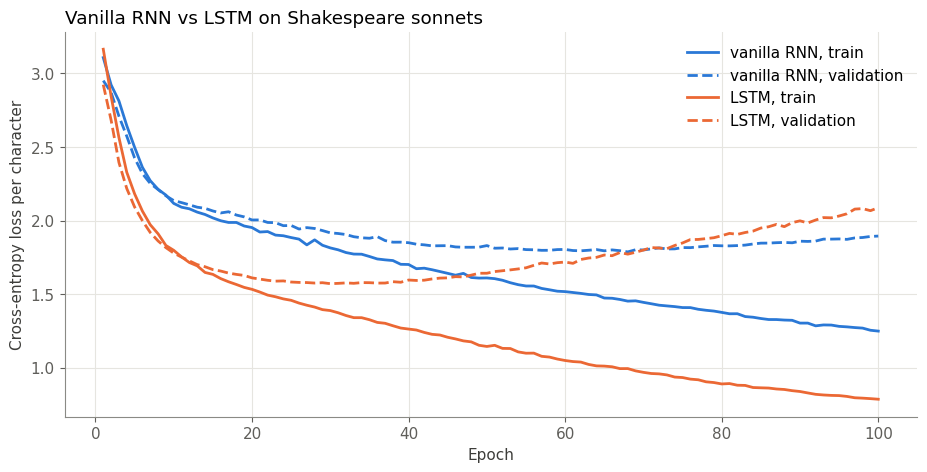

model          train loss     val loss        best val loss
vanilla RNN         1.249        1.895                1.788
LSTM                0.787        2.088                1.572


In [18]:
class CharLSTM(nn.Module):
    def __init__(self, num_tokens, emb_size=64, hidden_size=256, num_layers=2, dropout=0.3):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.emb = nn.Embedding(num_tokens, emb_size)
        self.lstm = nn.LSTM(emb_size, hidden_size, num_layers=num_layers, dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.hid_to_logits = nn.Linear(hidden_size, num_tokens)

    def forward(self, x, state):
        out, state = self.lstm(self.emb(x), state)
        return self.hid_to_logits(self.dropout(out)), state

    def initial_state(self, batch_size):
        zeros = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        return zeros, zeros.clone()


torch.manual_seed(0)
char_lstm = CharLSTM(num_tokens)
print(char_lstm)
print('parameters:', sum(p.numel() for p in char_lstm.parameters()))
lstm_history = train(char_lstm, N_EPOCHS)

plot_losses({'vanilla RNN': rnn_history, 'LSTM': lstm_history}, 'Vanilla RNN vs LSTM on Shakespeare sonnets')
print('%-12s %12s %12s %20s' % ('model', 'train loss', 'val loss', 'best val loss'))
for name, h in (('vanilla RNN', rnn_history), ('LSTM', lstm_history)):
    print('%-12s %12.3f %12.3f %20.3f' % (name, h['train_loss'][-1], h['val_loss'][-1], min(h['val_loss'])))

**Does the final loss become better?** 
Да.
- Лучший validation loss у LSTM — **1.572** (30-я эпоха), у vanilla RNN — 1.790. Train loss у LSTM ниже на всех эпохах.
- LSTM учится быстрее: уже к 10-й эпохе её validation loss подходит к лучшему результату RNN
- В LSTM 868 тысяч параметров, в 10 раз больше, чем в RNN, а текста всего 90 тысяч символов. Поэтому она начинает переобучаться раньше: после 30-й эпохи validation loss растёт и к 100-й доходит до 2.09, хотя train loss падает до 0.79. Благодаря early stopping дальше используются веса 30-й эпохи.

В колонке `val loss` таблицы - значение на последней эпохе, а в `best val loss` — на лучшей. 
Сами модели после обучения восстановлены на лучшую эпоху.

Generate text using the trained net with different `temperature` parameter: `[0.1, 0.2, 0.5, 1.0, 2.0]`.

Evaluate the results visually, try to interpret them.

In [19]:
for temperature in [0.1, 0.2, 0.5, 1.0, 2.0]:
    np.random.seed(0)
    print('=' * 25, 'temperature', temperature, '=' * 25)
    print(generate_sample(char_lstm, seed_phrase='shall i compare thee', max_length=400, temperature=temperature))
    print()

========================= temperature 0.1 =========================
shall i compare thee the strange,
  and then the strange the strange thee the strange,
  and then the strange thee the strange,
  the world the stars the strange thee the strange,
  the canker shall shall the strange thee,
    then the strange the world of the strange thee,
    then the strange thee the strange thee the strange,
  and then the strange the strange thee the strange,
  the world the 

========================= temperature 0.2 =========================
shall i compare thee the strong,
  and then the stars and there is the sweet some shall thee.

  xxvii

  the world the world the strange thee the strange,
  the world to the strange the strange thee the true,
  and then the strange the strange thee the strange,
  that thou art the world of thee,
    then thou mayst the shall the strange thee the strange,
  the world the stars the world thee thou 

========================= temperature 0.5 ==================

**Как влияет температура.** 
Логиты делятся на температуру перед softmax. При `T < 1` распределение становится острее и модель выбирает самые вероятные символы, при `T > 1` ближе к равномерному.
- **0.1–0.2.** Жадный выбор. Модель зацикливается на самых вероятных фразах (`the strange thee the strange`, `the world`). Слова настоящие, но текст вода.
- **0.5.** В основном настоящие слова и шекспировские обороты (`thou art beauty of thy self`), правильные переносы строк и отступы в заключительных двустишиях. Смысловой нагрузки нет.
- **1.0.** Сэмплирование из выученного распределения как есть. Текст разнообразнее, но выдуманных слов заметно больше (`bastous`, `crosk'd`).
- **2.0.** Распределение почти равномерное: случайные буквы и знаки препинания. От выученного остается только разбивка на строки.

### Saving and loading models

Save the model to the disk, then load it and generate text. Examples are available [here](https://pytorch.org/tutorials/beginner/saving_loading_models.html]).

In [20]:
torch.save(char_lstm.state_dict(), 'char_lstm.pt')

loaded_lstm = CharLSTM(num_tokens)
loaded_lstm.load_state_dict(torch.load('char_lstm.pt'))
loaded_lstm.eval()

np.random.seed(42)
original_sample = generate_sample(char_lstm, seed_phrase='my love is', max_length=300, temperature=0.5)
np.random.seed(42)
loaded_sample = generate_sample(loaded_lstm, seed_phrase='my love is', max_length=300, temperature=0.5)

print(loaded_sample)
print()
print('Loaded model generates exactly the same text:', original_sample == loaded_sample)
print('Validation loss: original %.4f, loaded %.4f' % (evaluate(char_lstm, val_data), evaluate(loaded_lstm, val_data)))

my love is the day,
  that the canker seem would make my love, thou art the death,
  that think this the still the fair in thee thee deeds
  and so my love shall doth should be earth,
  some art the hast of the canker after thee,
    for the star and the world not summer,
  the eyes the sure and the

Loaded model generates exactly the same text: True
Validation loss: original 1.5717, loaded 1.5717


### References
1. <a href='http://karpathy.github.io/2015/05/21/rnn-effectiveness/'> Andrew Karpathy blog post about RNN. </a> 
There are several examples of genration: Shakespeare texts, Latex formulas, Linux Sourse Code and children names.
2. <a href='https://github.com/karpathy/char-rnn'> Repo with char-rnn code </a>
3. Cool repo with PyTorch examples: [link](https://github.com/spro/practical-pytorch`)